# Unsupervised Exploration — LED Solder-Joint Void Features

**Study:** Predict LED solder-joint thermal-resistance failure from X-ray void features.  
**Goal:** Compare dimensionality-reduction methods and run clustering, visualising with labels for interpretation.  
**Note:** This notebook is for *exploration only*. The 2-D embeddings are **not** used as features in the supervised model.

> **Environment note:** `umap-learn` is not part of the standard Anaconda install.  
> Install once with: `pip install umap-learn`

## 1. Setup & Imports

In [9]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA, KernelPCA
from sklearn.manifold import Isomap, TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
)
from sklearn.neighbors import NearestNeighbors

try:
    import umap
except ImportError:
    raise ImportError(
        "umap-learn is not installed. Run: pip install umap-learn"
    )

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
np.random.seed(42)

print("Imports OK")

Imports OK


## 2. Load Data

In [10]:
DATA_PATH = "../data/processed/model_dataset.csv"

df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape}")
df.head()

Shape: (1470, 45)


,unit_id,led_type,paste,panel,led,has_thermal_pad,thermal_void_area_frac,thermal_centroid_x,thermal_centroid_y,thermal_q_NW,...,label_status,tsc_fail,tsc_fail_sustained,last_cycle,rth_500,rth_end,rth_increase,rth_increase_pct,ri_500_pct,ri_max_pct
0,FC-GB2_SAC107-BiIn_P1_L02,FC-GB2,SAC107-BiIn,1,2,1.0,0.020928,0.615373,0.072432,0.000000,...,ok,500.0,500.0,1500.0,12.084356,29.839828,20.264891,211.645181,26.208211,211.645181
1,FC-GB2_SAC107-BiIn_P1_L03,FC-GB2,SAC107-BiIn,1,3,1.0,0.010285,-0.529327,0.457574,0.174419,...,ok,750.0,750.0,1500.0,10.744296,16.605415,7.029735,73.412388,12.204009,73.412388
2,FC-GB2_SAC107-BiIn_P1_L04,FC-GB2,SAC107-BiIn,1,4,1.0,0.045802,0.497724,0.012773,0.000000,...,ok,750.0,750.0,1500.0,9.556831,14.151400,4.538046,47.205646,-0.587963,47.205646
3,FC-GB2_SAC107-BiIn_P1_L05,FC-GB2,SAC107-BiIn,1,5,1.0,0.004186,-0.166625,0.228571,0.000000,...,ok,500.0,500.0,1500.0,11.691541,16.517620,6.980075,73.185239,22.584383,73.185239
4,FC-GB2_SAC107-BiIn_P1_L06,FC-GB2,SAC107-BiIn,1,6,1.0,0.002511,0.026549,0.486486,0.000000,...,ok,500.0,500.0,1500.0,12.173268,17.237209,7.815018,82.942673,29.197835,82.942673


### 2a. Derive binary failure label

`tsc_fail` in the CSV stores the *cycle number* at which thermal-resistance failure was detected,
or `NaN` for samples that never failed within the test window.
We derive `tsc_fail_binary` (0 = no failure, 1 = failure detected) for use as a categorical hue.

If `tsc_fail` is already 0/1 in your dataset version, the code below is a no-op (both paths produce the same result).

In [11]:
unique_tsc = df["tsc_fail"].dropna().unique()
already_binary = set(unique_tsc).issubset({0, 1, 0.0, 1.0})

if already_binary:
    df["tsc_fail_binary"] = df["tsc_fail"].fillna(0).astype(int)
    print("tsc_fail is already 0/1 — used as-is.")
else:
    # Cycle-number column: NaN = no failure, non-NaN = failure detected
    df["tsc_fail_binary"] = df["tsc_fail"].notna().astype(int)
    print(
        f"tsc_fail contains cycle values {sorted(unique_tsc)[:6]} ...\n"
        "Derived tsc_fail_binary: 1 = failure detected, 0 = no failure."
    )

print(df["tsc_fail_binary"].value_counts().to_string())

tsc_fail contains cycle values [np.float64(100.0), np.float64(150.0), np.float64(250.0), np.float64(350.0), np.float64(500.0), np.float64(750.0)] ...
Derived tsc_fail_binary: 1 = failure detected, 0 = no failure.
tsc_fail_binary
1    1055
0     415


## 3. Prepare Feature Matrix

In [12]:
feat_cols = [c for c in df.columns if c.startswith(("thermal_", "electrical_mean_"))]
print(f"Feature columns ({len(feat_cols)}):")
print(feat_cols)

# thermal_* features are NaN for 2-pad LEDs (no thermal pad);
# has_thermal_pad already carries the group signal, so fill NaN with 0.
imputer = SimpleImputer(strategy="constant", fill_value=0)
X_raw = imputer.fit_transform(df[feat_cols])

scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

n_features = X.shape[1]
print(f"\nFeature matrix shape: {X.shape}")
print(f"NaN count after imputation: {np.isnan(X).sum()}")

Feature columns (22):
['thermal_void_area_frac', 'thermal_centroid_x', 'thermal_centroid_y', 'thermal_q_NW', 'thermal_q_NE', 'thermal_q_SW', 'thermal_q_SE', 'thermal_cluster_count', 'thermal_mean_circularity', 'thermal_largest_void_frac', 'thermal_edge_proximity_min', 'electrical_mean_void_area_frac', 'electrical_mean_centroid_x', 'electrical_mean_centroid_y', 'electrical_mean_q_NW', 'electrical_mean_q_NE', 'electrical_mean_q_SW', 'electrical_mean_q_SE', 'electrical_mean_cluster_count', 'electrical_mean_mean_circularity', 'electrical_mean_largest_void_frac', 'electrical_mean_edge_proximity_min']

Feature matrix shape: (1470, 22)
NaN count after imputation: 0


In [13]:
X.shape

(1470, 22)

## 4. Fit All 5 Embeddings

We fit PCA, Kernel PCA, Isomap, UMAP, and t-SNE and store each 2-D embedding in a dict.
Wall time is printed per method.

In [14]:
embeddings = {}

# --- PCA ---
t0 = time.perf_counter()
pca2 = PCA(n_components=2, random_state=42)
embeddings["PCA"] = pca2.fit_transform(X)
print(f"PCA        : {time.perf_counter() - t0:.2f}s")

# --- Kernel PCA ---
# gamma controls RBF locality: small gamma = global structure, large gamma = local structure.
# 1/n_features is a common heuristic (same as the default in sklearn SVC).
t0 = time.perf_counter()
kpca = KernelPCA(n_components=2, kernel="rbf", gamma=1 / n_features, random_state=42)
embeddings["KernelPCA"] = kpca.fit_transform(X)
print(f"KernelPCA  : {time.perf_counter() - t0:.2f}s")

# --- Isomap ---
t0 = time.perf_counter()
iso = Isomap(n_components=2, n_neighbors=15)
embeddings["Isomap"] = iso.fit_transform(X)
print(f"Isomap     : {time.perf_counter() - t0:.2f}s")

# --- UMAP ---
t0 = time.perf_counter()
umap_model = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=42)
embeddings["UMAP"] = umap_model.fit_transform(X)
print(f"UMAP       : {time.perf_counter() - t0:.2f}s")

# --- t-SNE ---
t0 = time.perf_counter()
tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init="pca",
    learning_rate="auto",
)
embeddings["t-SNE"] = tsne.fit_transform(X)
print(f"t-SNE      : {time.perf_counter() - t0:.2f}s")

print("\nAll embeddings fitted.")

PCA        : 0.00s
KernelPCA  : 0.07s


c:\Users\JPagtalu\Documents\Joanna\MEng AI\ai221\ai221_project\ai221_env\Lib\site-packages\sklearn\manifold\_isomap.py:386: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
c:\Users\JPagtalu\Documents\Joanna\MEng AI\ai221\ai221_project\ai221_env\Lib\site-packages\scipy\sparse\_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


Isomap     : 0.43s


c:\Users\JPagtalu\Documents\Joanna\MEng AI\ai221\ai221_project\ai221_env\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP       : 9.00s
t-SNE      : 2.17s

All embeddings fitted.


In [15]:
print(embeddings)
print(embeddings.keys())
print(embeddings['PCA'].shape)

{'PCA': array([[-1.44423353, -0.86889446],
       [-0.64256772, -4.82728331],
       [-1.53716081, -3.86067073],
       ...,
       [-1.02508477,  0.4712743 ],
       [-1.9104343 , -0.28180145],
       [-1.59154443,  0.2964795 ]], shape=(1470, 2)), 'KernelPCA': array([[-0.20168156,  0.04444223],
       [-0.1831028 ,  0.34563974],
       [-0.19206008,  0.26503638],
       ...,
       [-0.20987974, -0.06315384],
       [-0.26240055, -0.02117383],
       [-0.27658198, -0.13656948]], shape=(1470, 2)), 'Isomap': array([[ -6.48800923,   0.74063352],
       [ -9.99589082,  12.26147583],
       [-12.28541644,  10.32072185],
       ...,
       [ -7.12511769,  -4.35410178],
       [ -6.19371127,   0.48521211],
       [ -8.74844976,  -2.67400578]], shape=(1470, 2)), 'UMAP': array([[16.30639839,  8.56403828],
       [19.09039497, -8.95618248],
       [18.28694916, -9.44996166],
       ...,
       [16.66577148,  6.34412336],
       [14.3164978 ,  8.65420151],
       [15.90399361,  7.49858141]], sha

## 5. Side-by-Side Visualisation — Coloured by `tsc_fail_binary`

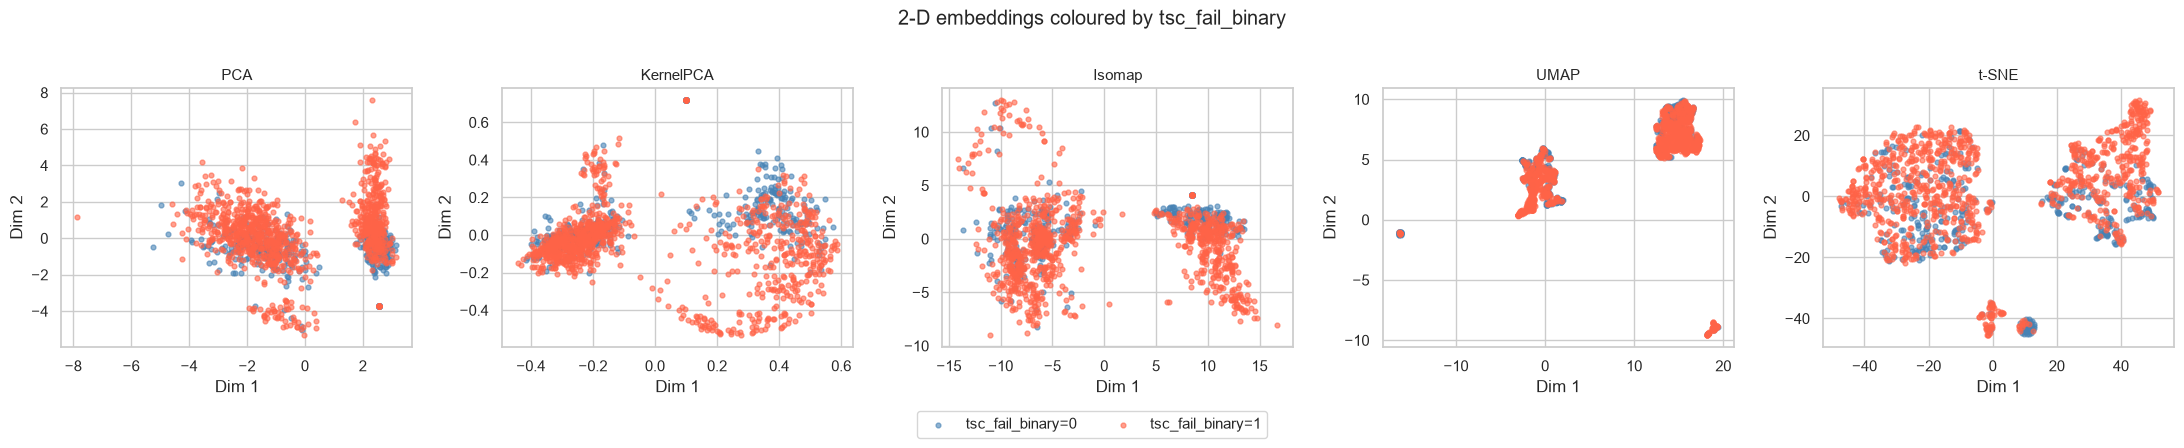

In [7]:
method_names = list(embeddings.keys())
hue_col = "tsc_fail_binary"
palette = {0: "steelblue", 1: "tomato"}

fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for ax, name in zip(axes, method_names):
    emb = embeddings[name]
    for val, colour in palette.items():
        mask = df[hue_col] == val
        ax.scatter(
            emb[mask, 0], emb[mask, 1],
            c=colour, s=12, alpha=0.6,
            label=f"{hue_col}={val}",
        )
    ax.set_title(name, fontsize=11)
    ax.set_xlabel("Dim 1")
    ax.set_ylabel("Dim 2")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("2-D embeddings coloured by tsc_fail_binary", y=1.01)
plt.tight_layout()
plt.show()

## 6. Panel-of-Panels — Methods × Label Types

Rows = dimensionality-reduction methods; columns = label types.  
`rth_increase_pct` uses a continuous `viridis` colour map; all others use `sns.scatterplot` with categorical hue.  
This is the **thesis diagnostic plot**.

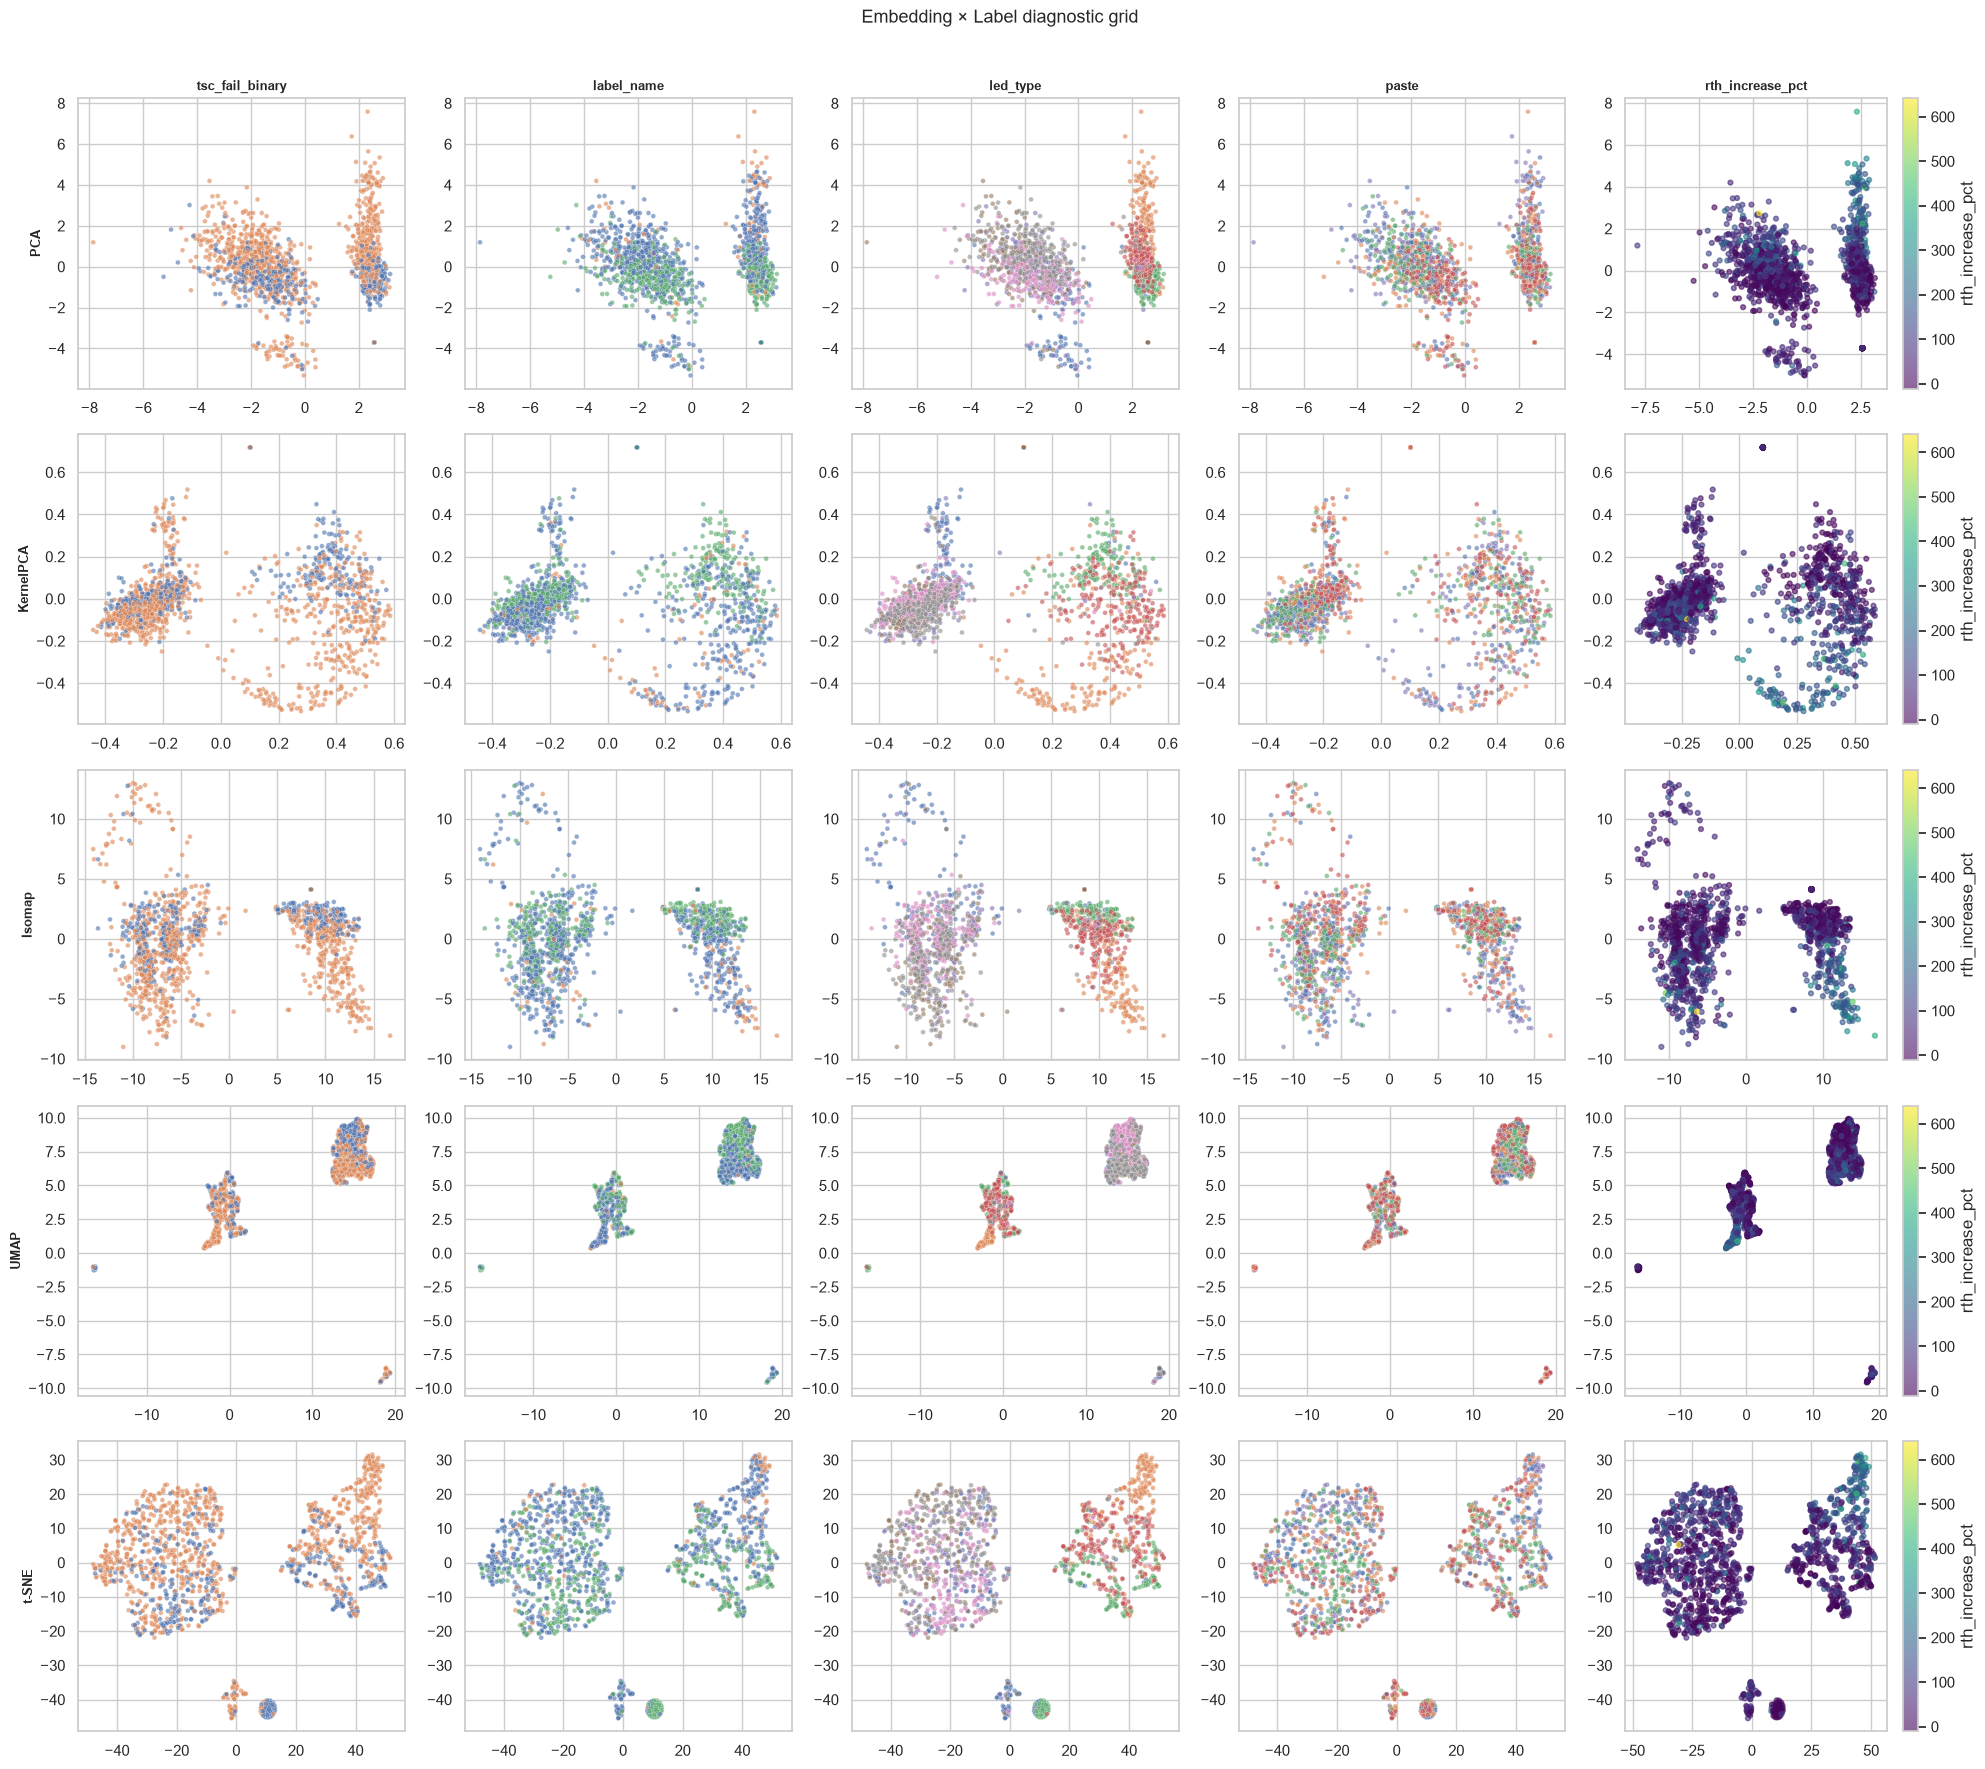

In [8]:
label_cols = ["tsc_fail_binary", "label_name", "led_type", "paste", "rth_increase_pct"]
n_methods = len(method_names)
n_labels = len(label_cols)

fig, axes = plt.subplots(
    n_methods, n_labels,
    figsize=(n_labels * 4, n_methods * 3.5),
    squeeze=False,
)

for row_idx, name in enumerate(method_names):
    emb = embeddings[name]
    emb_df = pd.DataFrame(emb, columns=["Dim1", "Dim2"])
    for col_idx, lbl in enumerate(label_cols):
        ax = axes[row_idx][col_idx]
        if lbl == "rth_increase_pct":
            sc = ax.scatter(
                emb_df["Dim1"], emb_df["Dim2"],
                c=df[lbl], cmap="viridis", s=12, alpha=0.6,
            )
            if col_idx == n_labels - 1:
                plt.colorbar(sc, ax=ax, label="rth_increase_pct")
        else:
            plot_df = emb_df.copy()
            plot_df[lbl] = df[lbl].values
            legend = col_idx == n_labels - 1
            sns.scatterplot(
                data=plot_df, x="Dim1", y="Dim2",
                hue=lbl, s=12, alpha=0.6,
                ax=ax,
                legend=legend,
            )
            if legend:
                ax.legend(
                    loc="upper left", bbox_to_anchor=(1.01, 1),
                    fontsize=7, markerscale=1.5,
                )

        if row_idx == 0:
            ax.set_title(lbl, fontsize=9, fontweight="bold")
        if col_idx == 0:
            ax.set_ylabel(name, fontsize=9, fontweight="bold")
        else:
            ax.set_ylabel("")
        ax.set_xlabel("")

fig.suptitle("Embedding \u00d7 Label diagnostic grid", y=1.01, fontsize=13)
plt.tight_layout()
plt.show()

## 7. PCA Explained-Variance Analysis

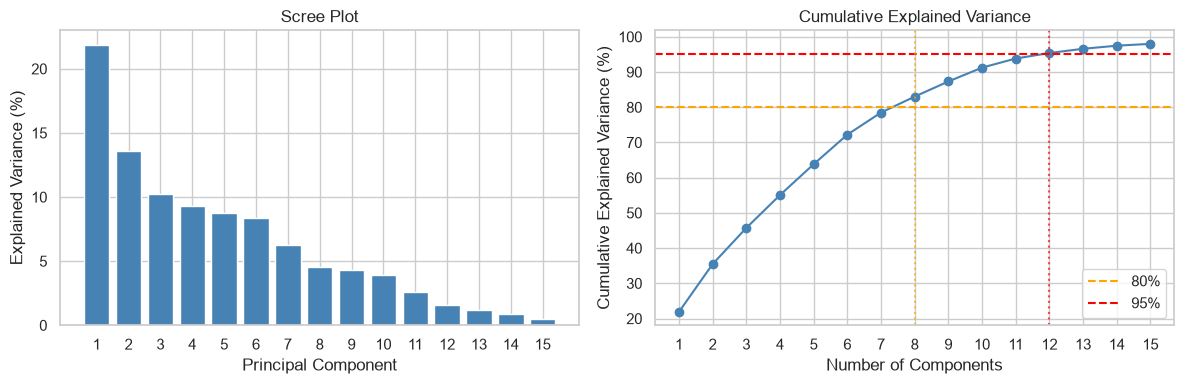

Components needed for 80% variance: 8
Components needed for 95% variance: 12


In [9]:
n_pca_components = min(len(feat_cols), 15)
pca_full = PCA(n_components=n_pca_components, random_state=42)
pca_full.fit(X)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)
components_80 = int(np.searchsorted(cumulative, 0.80)) + 1
components_95 = int(np.searchsorted(cumulative, 0.95)) + 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Scree plot
ax = axes[0]
ax.bar(range(1, n_pca_components + 1), explained * 100, color="steelblue")
ax.set_xlabel("Principal Component")
ax.set_ylabel("Explained Variance (%)")
ax.set_title("Scree Plot")
ax.set_xticks(range(1, n_pca_components + 1))

# Cumulative variance
ax = axes[1]
ax.plot(range(1, n_pca_components + 1), cumulative * 100, "o-", color="steelblue")
ax.axhline(80, color="orange", linestyle="--", label="80%")
ax.axhline(95, color="red", linestyle="--", label="95%")
ax.axvline(components_80, color="orange", linestyle=":", alpha=0.7)
ax.axvline(components_95, color="red", linestyle=":", alpha=0.7)
ax.set_xlabel("Number of Components")
ax.set_ylabel("Cumulative Explained Variance (%)")
ax.set_title("Cumulative Explained Variance")
ax.set_xticks(range(1, n_pca_components + 1))
ax.legend()

plt.tight_layout()
plt.show()

print(f"Components needed for 80% variance: {components_80}")
print(f"Components needed for 95% variance: {components_95}")

## 8. PCA Component Loadings

Bar charts of the loadings for PC1 and PC2, labelled by feature name.

**Interpretation stub (fill in after viewing the plot):**  
- PC1 appears to encode ___ (e.g., overall void density / spatial distribution)  
- PC2 appears to encode ___ (e.g., quadrant asymmetry / centroid offset)  

High-magnitude loadings reveal which raw features drive each principal direction.

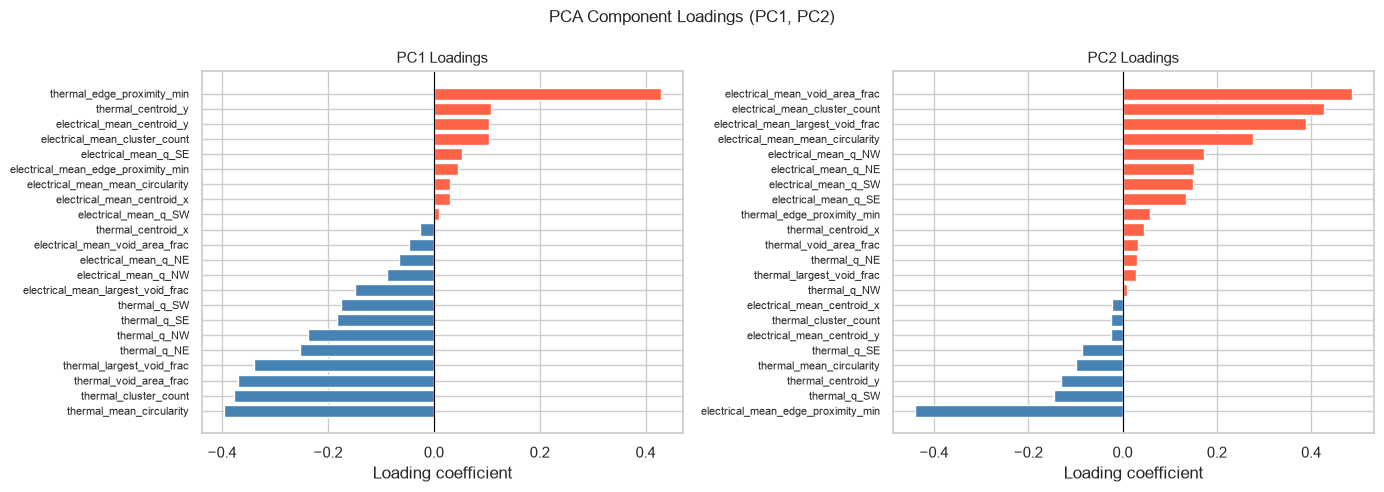

In [10]:
loadings = pd.DataFrame(
    pca_full.components_[:2].T,
    index=feat_cols,
    columns=["PC1", "PC2"],
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

for ax, pc in zip(axes, ["PC1", "PC2"]):
    sorted_loadings = loadings[pc].sort_values()
    colours = ["tomato" if v > 0 else "steelblue" for v in sorted_loadings]
    ax.barh(sorted_loadings.index, sorted_loadings.values, color=colours)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{pc} Loadings", fontsize=11)
    ax.set_xlabel("Loading coefficient")
    ax.tick_params(axis="y", labelsize=8)

plt.suptitle("PCA Component Loadings (PC1, PC2)", fontsize=12)
plt.tight_layout()
plt.show()

## 9. UMAP Hyperparameter Sweep

3 × 3 grid across `n_neighbors ∈ [5, 15, 50]` and `min_dist ∈ [0.0, 0.1, 0.5]`, coloured by `tsc_fail_binary`.

> **Interpretation rule:** Structural patterns that *persist across all 9 panels* are likely real data
> structure. Clusters that appear in only one or two settings are UMAP hyperparameter artefacts — do not over-interpret them.

c:\Users\JPagtalu\Documents\Joanna\MEng AI\ai221\ai221_project\ai221_env\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\JPagtalu\Documents\Joanna\MEng AI\ai221\ai221_project\ai221_env\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\JPagtalu\Documents\Joanna\MEng AI\ai221\ai221_project\ai221_env\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\JPagtalu\Documents\Joanna\MEng AI\ai221\ai221_project\ai221_env\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\JPagtalu\Documents\Joanna\MEng AI\ai221\ai221_project\ai221_env\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jo

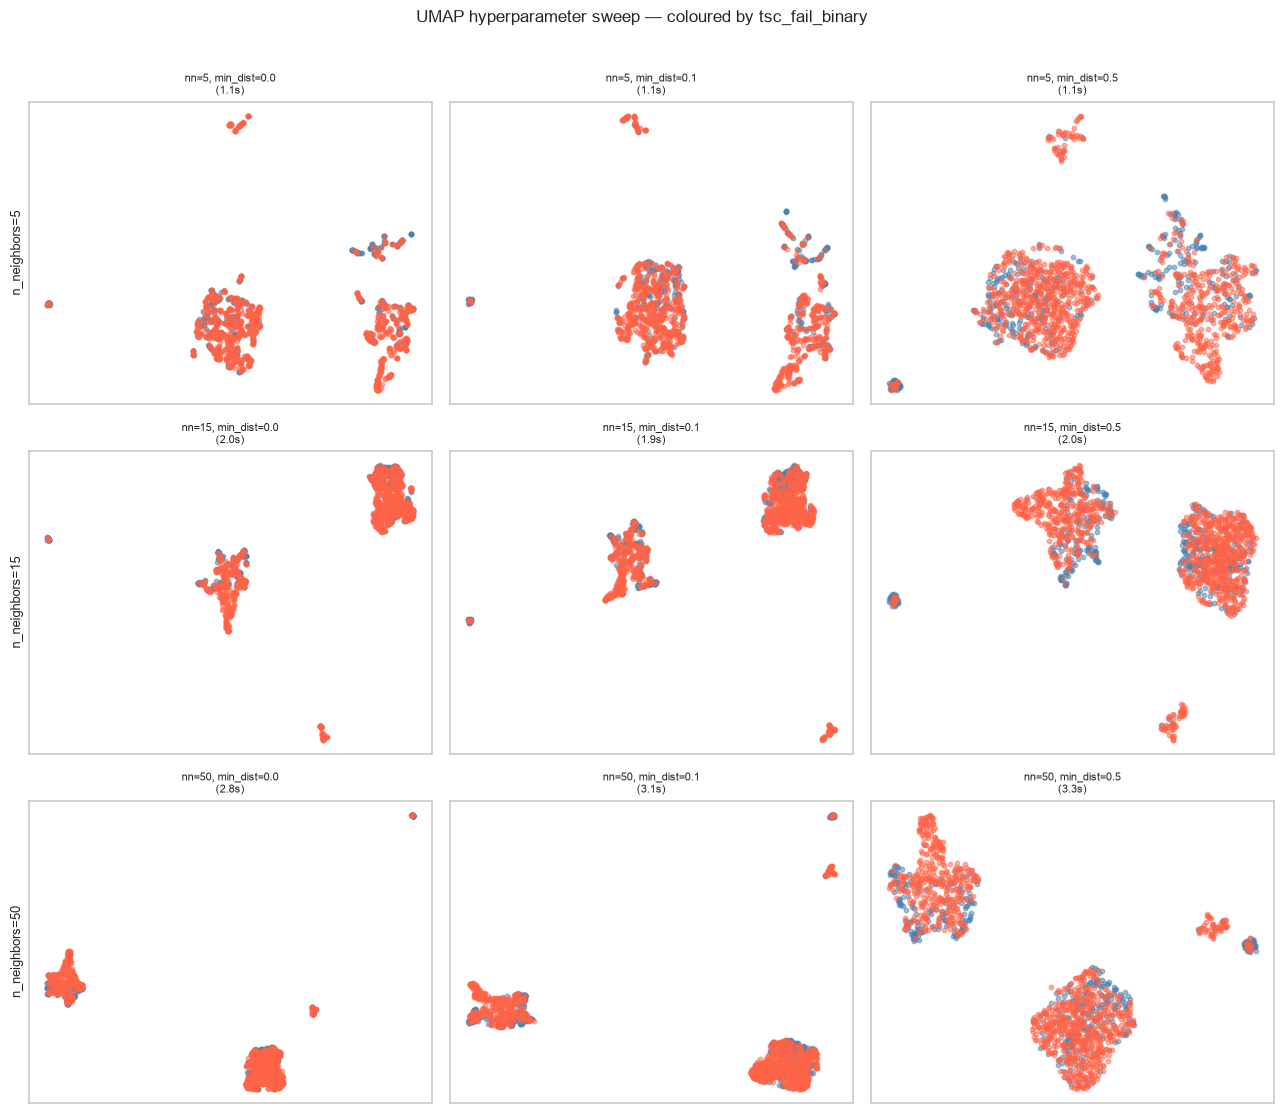

In [11]:
n_neighbors_grid = [5, 15, 50]
min_dist_grid = [0.0, 0.1, 0.5]

fig, axes = plt.subplots(
    len(n_neighbors_grid), len(min_dist_grid),
    figsize=(13, 11),
    squeeze=False,
)

for row_i, nn in enumerate(n_neighbors_grid):
    for col_i, md in enumerate(min_dist_grid):
        t0 = time.perf_counter()
        emb = umap.UMAP(
            n_components=2,
            n_neighbors=nn,
            min_dist=md,
            random_state=42,
        ).fit_transform(X)
        elapsed = time.perf_counter() - t0

        ax = axes[row_i][col_i]
        for val, colour in {0: "steelblue", 1: "tomato"}.items():
            mask = df["tsc_fail_binary"] == val
            ax.scatter(emb[mask, 0], emb[mask, 1], c=colour, s=10, alpha=0.5)
        ax.set_title(
            f"nn={nn}, min_dist={md}\n({elapsed:.1f}s)",
            fontsize=8,
        )
        ax.set_xticks([])
        ax.set_yticks([])

    axes[row_i][0].set_ylabel(f"n_neighbors={nn}", fontsize=9)

fig.suptitle(
    "UMAP hyperparameter sweep — coloured by tsc_fail_binary",
    fontsize=12, y=1.01,
)
plt.tight_layout()
plt.show()

## 10. Clustering — K-Means on PCA Space

In [1]:
X

NameError: name 'X' is not defined

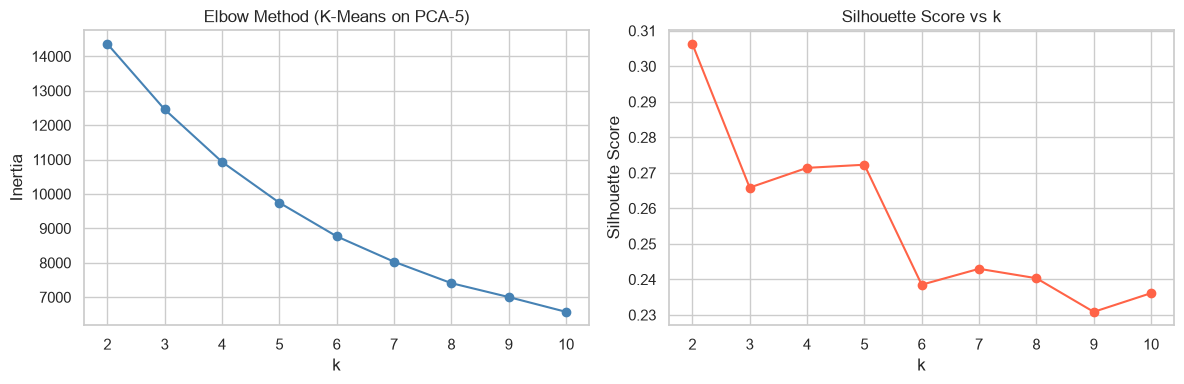


Silhouette scores:
  k=2: 0.3063
  k=3: 0.2658
  k=4: 0.2714
  k=5: 0.2723
  k=6: 0.2385
  k=7: 0.2430
  k=8: 0.2403
  k=9: 0.2309
  k=10: 0.2361


In [12]:
# Reduce to top 5 PCs as the clustering space
pca5 = PCA(n_components=5, random_state=42)
X_pca5 = pca5.fit_transform(X)

k_range = range(2, 11)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = km.fit_predict(X_pca5)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_pca5, labels_k))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(list(k_range), inertias, "o-", color="steelblue")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow Method (K-Means on PCA-5)")
axes[0].set_xticks(list(k_range))

axes[1].plot(list(k_range), sil_scores, "o-", color="tomato")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Score vs k")
axes[1].set_xticks(list(k_range))

plt.tight_layout()
plt.show()

print("\nSilhouette scores:")
for k, s in zip(k_range, sil_scores):
    print(f"  k={k}: {s:.4f}")

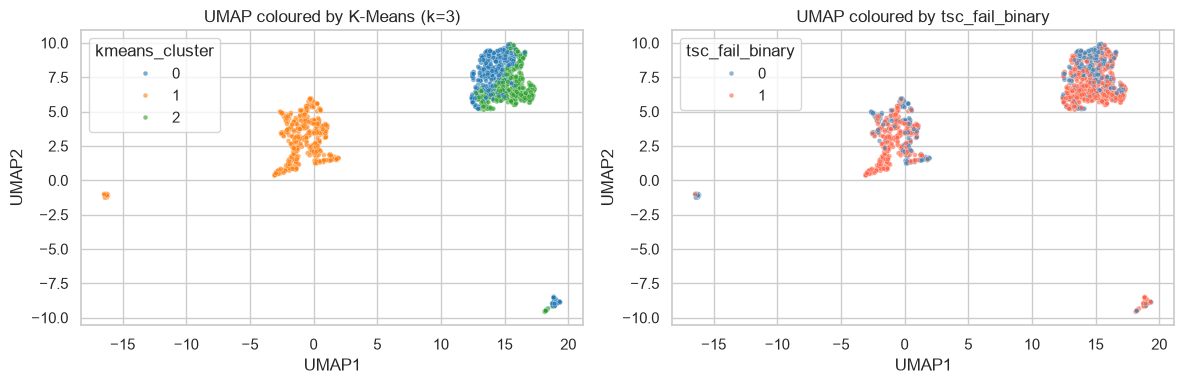

Contingency table (kmeans_cluster vs tsc_fail_binary):
tsc_fail_binary    0    1
cluster                  
0                140  294
1                204  405
2                 71  356

Adjusted Rand Index (K-Means vs tsc_fail_binary): 0.0035
Normalised Mutual Info (K-Means vs tsc_fail_binary): 0.0174


In [13]:
# Pick k from the elbow / silhouette plots — adjust here after viewing the charts above.
K_CHOSEN = 3  # <-- update based on elbow + silhouette inspection

km_final = KMeans(n_clusters=K_CHOSEN, random_state=42, n_init=10)
kmeans_clusters = km_final.fit_predict(X_pca5)
df["kmeans_cluster"] = kmeans_clusters

# Scatter UMAP coloured by (a) cluster, (b) tsc_fail_binary
umap_emb = embeddings["UMAP"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

umap_df = pd.DataFrame(umap_emb, columns=["UMAP1", "UMAP2"])
umap_df["kmeans_cluster"] = kmeans_clusters
umap_df["tsc_fail_binary"] = df["tsc_fail_binary"].values

sns.scatterplot(
    data=umap_df, x="UMAP1", y="UMAP2",
    hue="kmeans_cluster", palette="tab10",
    s=12, alpha=0.6, ax=axes[0],
)
axes[0].set_title(f"UMAP coloured by K-Means (k={K_CHOSEN})")

sns.scatterplot(
    data=umap_df, x="UMAP1", y="UMAP2",
    hue="tsc_fail_binary", palette={0: "steelblue", 1: "tomato"},
    s=12, alpha=0.6, ax=axes[1],
)
axes[1].set_title("UMAP coloured by tsc_fail_binary")

plt.tight_layout()
plt.show()

# Contingency table and cluster quality vs ground-truth label
print("Contingency table (kmeans_cluster vs tsc_fail_binary):")
print(pd.crosstab(
    kmeans_clusters, df["tsc_fail_binary"],
    rownames=["cluster"], colnames=["tsc_fail_binary"],
))

ari_km = adjusted_rand_score(df["tsc_fail_binary"], kmeans_clusters)
nmi_km = normalized_mutual_info_score(df["tsc_fail_binary"], kmeans_clusters)
print(f"\nAdjusted Rand Index (K-Means vs tsc_fail_binary): {ari_km:.4f}")
print(f"Normalised Mutual Info (K-Means vs tsc_fail_binary): {nmi_km:.4f}")

## 11. Clustering — DBSCAN on UMAP Embedding

DBSCAN runs on the **2-D UMAP embedding**, not on raw features.  
UMAP compresses the neighbourhood structure into 2-D first, making DBSCAN much more effective.  

`eps` controls the neighbourhood radius and needs tuning per dataset.  
The **k-distance plot** (sorted 10-NN distance) shows a natural "knee" which is a good starting `eps`.

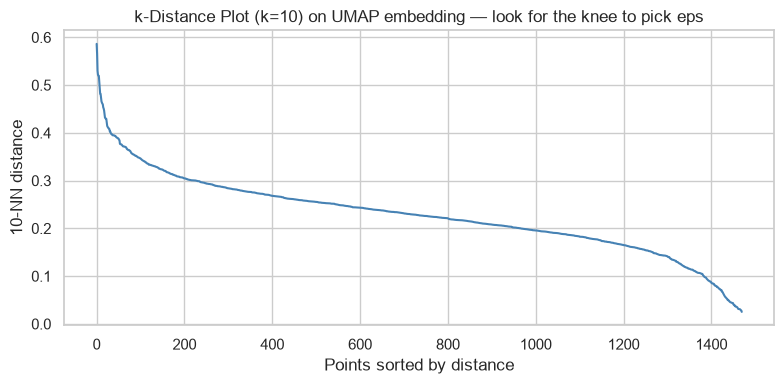

In [14]:
# k-distance plot to guide eps selection
k_nn = 10
nbrs = NearestNeighbors(n_neighbors=k_nn).fit(umap_emb)
distances, _ = nbrs.kneighbors(umap_emb)
k_distances = np.sort(distances[:, -1])[::-1]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_distances, color="steelblue")
ax.set_xlabel("Points sorted by distance")
ax.set_ylabel(f"{k_nn}-NN distance")
ax.set_title(
    f"k-Distance Plot (k={k_nn}) on UMAP embedding"
    " — look for the knee to pick eps"
)
plt.tight_layout()
plt.show()

DBSCAN: 4 clusters, 0 noise points (0.0%)


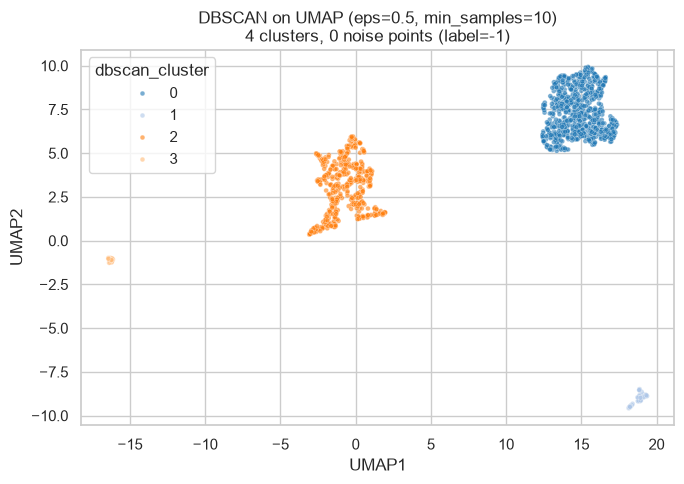


ARI  (DBSCAN vs tsc_fail_binary, non-noise): 0.0230
NMI  (DBSCAN vs tsc_fail_binary, non-noise): 0.0288

Contingency table (DBSCAN cluster vs tsc_fail_binary):
tsc_fail_binary    0    1
dbscan_cluster           
0                206  599
1                  5   51
2                165  392
3                 39   13


In [15]:
# Tune EPS_CHOSEN based on the knee in the k-distance plot above.
EPS_CHOSEN = 0.5  # <-- adjust after viewing k-distance plot
MIN_SAMPLES = 10

dbscan = DBSCAN(eps=EPS_CHOSEN, min_samples=MIN_SAMPLES)
dbscan_labels = dbscan.fit_predict(umap_emb)
df["dbscan_cluster"] = dbscan_labels

n_clusters_db = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = (dbscan_labels == -1).sum()
print(
    f"DBSCAN: {n_clusters_db} clusters, "
    f"{n_noise} noise points ({n_noise / len(dbscan_labels) * 100:.1f}%)"
)

fig, ax = plt.subplots(figsize=(7, 5))
db_df = pd.DataFrame(umap_emb, columns=["UMAP1", "UMAP2"])
db_df["dbscan_cluster"] = dbscan_labels.astype(str)

sns.scatterplot(
    data=db_df, x="UMAP1", y="UMAP2",
    hue="dbscan_cluster", palette="tab20",
    s=12, alpha=0.6, ax=ax,
)
ax.set_title(
    f"DBSCAN on UMAP (eps={EPS_CHOSEN}, min_samples={MIN_SAMPLES})\n"
    f"{n_clusters_db} clusters, {n_noise} noise points (label=-1)"
)
plt.tight_layout()
plt.show()

# Only compute metrics for non-noise points
valid_mask = dbscan_labels != -1
if valid_mask.sum() > 0 and len(set(dbscan_labels[valid_mask])) > 1:
    ari_db = adjusted_rand_score(
        df.loc[valid_mask, "tsc_fail_binary"], dbscan_labels[valid_mask]
    )
    nmi_db = normalized_mutual_info_score(
        df.loc[valid_mask, "tsc_fail_binary"], dbscan_labels[valid_mask]
    )
    print(f"\nARI  (DBSCAN vs tsc_fail_binary, non-noise): {ari_db:.4f}")
    print(f"NMI  (DBSCAN vs tsc_fail_binary, non-noise): {nmi_db:.4f}")
else:
    print("Insufficient clusters for ARI/NMI — try adjusting eps.")

print("\nContingency table (DBSCAN cluster vs tsc_fail_binary):")
print(pd.crosstab(
    dbscan_labels,
    df["tsc_fail_binary"],
    rownames=["dbscan_cluster"],
    colnames=["tsc_fail_binary"],
))

## 12. Save Embeddings

In [16]:
OUTPUT_PATH = "../data/processed/unsupervised_embeddings.csv"

out_df = pd.DataFrame()
out_df["unit_id"] = df["unit_id"]
out_df["led_type"] = df["led_type"]
out_df["paste"] = df["paste"]
out_df["tsc_fail"] = df["tsc_fail"]
out_df["tsc_fail_binary"] = df["tsc_fail_binary"]
out_df["label_name"] = df["label_name"]
out_df["rth_increase_pct"] = df["rth_increase_pct"]

method_prefix_map = {
    "PCA": "pca",
    "KernelPCA": "kpca",
    "Isomap": "isomap",
    "UMAP": "umap",
    "t-SNE": "tsne",
}

for method_name, prefix in method_prefix_map.items():
    emb = embeddings[method_name]
    out_df[f"{prefix}_1"] = emb[:, 0]
    out_df[f"{prefix}_2"] = emb[:, 1]

out_df["kmeans_cluster"] = df["kmeans_cluster"]
out_df["dbscan_cluster"] = df["dbscan_cluster"]

out_df.to_csv(OUTPUT_PATH, index=False)
print(f"Saved {out_df.shape[0]} rows \u00d7 {out_df.shape[1]} cols to: {OUTPUT_PATH}")
print(out_df.head(2))

Saved 1470 rows × 19 cols to: ../data/processed/unsupervised_embeddings.csv
                     unit_id led_type        paste  tsc_fail  tsc_fail_binary  \
0  FC-GB2_SAC107-BiIn_P1_L02   FC-GB2  SAC107-BiIn     500.0                1   
1  FC-GB2_SAC107-BiIn_P1_L03   FC-GB2  SAC107-BiIn     750.0                1   

         label_name  rth_increase_pct     pca_1     pca_2    kpca_1    kpca_2  \
0  Mid-life failure        211.645181 -1.444234 -0.868894 -0.201682  0.044442   
1  Mid-life failure         73.412388 -0.642568 -4.827283 -0.183103  0.345640   

   isomap_1   isomap_2     umap_1    umap_2     tsne_1     tsne_2  \
0 -6.488009   0.740634  16.306398  8.564038 -33.908985 -14.834377   
1 -9.995891  12.261476  19.090395 -8.956182  -1.276908 -36.683117   

   kmeans_cluster  dbscan_cluster  
0               2               0  
1               0               1  


## 13. Summary

Fill in after running the notebook:

- **Which methods separated `tsc_fail_binary` visually?**  
  _[user fills: e.g., UMAP showed the clearest separation; PCA showed no separation]_

- **Does `led_type` dominate the embedding structure?**  
  _[user fills: yes / no / partially — if `led_type` dominates, the void features mainly reflect LED design rather than failure mechanism]_

- **ARI / NMI of best clustering vs `tsc_fail_binary`:**  
  _[user fills: K-Means ARI=x.xx, NMI=x.xx; DBSCAN ARI=x.xx, NMI=x.xx]_

---

### Important: Do Not Use These Embeddings as Supervised-Model Features

| Method | Can be used as supervised features? | Notes |
|---|---|---|
| **PCA** | **Yes** | Fit on train only, transform test with same object. Interpretable, stable. |
| **Kernel PCA** | Technically yes, with caveats | Fit on train, transform test with same kernel + gamma. Loses interpretability and has O(n\u00b2) memory cost. |
| **Isomap** | No | Transductive: test-set projection is unreliable and leaks neighbourhood structure. |
| **UMAP** | No | Stochastic; test-set `transform()` is not guaranteed to align with the training manifold. Use for visualisation only. |
| **t-SNE** | No | Has no `transform()` method for new data. Visualisation only. |

**Rule:** Use the PCA component scores from Section 7 (fit `PCA` on train split, call `.transform()` on test split) as the only legitimate reusable supervised features from this notebook.